In this notebook, we'll build a simple **Convolutional Neural Network** (CNN) to classify handwritten digits using the MNIST dataset.

MNIST contains **70,000** grayscale images of handwritten digits from 0 to 9. We will use **60,000** images to train our model and **10,000** images to evaluate how well it recognizes digits it hasn't seen before.

By the end, we will have a CNN that takes an image as input and predicts which digit it represents.

Before building our CNN, we need to import the libraries that provide the tools for our project.

PyTorch (torch): Used to build and train our neural network.

Matplotlib (pyplot): Used to visualize images and display results.

NumPy (numpy): Provides methods for numerical computations.

Torchvision (datasets, transforms): Helps us load the MNIST dataset and prepare the images for our model.

Let's import these libraries before moving on to the dataset.

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets, transforms

Our CNN needs images to learn from. We will use the MNIST dataset, which consists of grayscale images of handwritten digits, each measuring 28 × 28 pixels.

We use transforms.ToTensor() to convert each image into a PyTorch tensor. This also scales its pixel values from the range 0–255 to the range 0–1.

We then load two separate datasets:

Training dataset: Contains 60,000 images that the model will learn from.

Test dataset: Contains 10,000 images that we will use to evaluate the trained model.

Keeping the test dataset separate helps us assess whether the model can recognize new images rather than simply memorize its training data.

In [ ]:
transform = transforms.ToTensor()
train_dataset = datasets.MNIST(root="./data",train=True,download=True,transform=transform)
test_dataset = datasets.MNIST(root="./data",train=False,download=True,transform=transform)

100%|██████████| 9.91M/9.91M [00:00<00:00, 37.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.04MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.67MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.21MB/s]


Before training a neural network, it is useful to understand the data we are working with.

We will inspect the number of images, the dimensions of an individual image, its label, and its minimum and maximum pixel values.

An image tensor with the shape [1, 28, 28] has three dimensions:

1 represents the grayscale channel.

28 represents the image height in pixels.

28 represents the image width in pixels.

The label tells us which digit the image represents.

In [ ]:
print("Number of training images:", len(train_dataset))
print("Number of test images:", len(test_dataset))

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

Number of training images: 60000
Number of test images: 10000
Image shape: torch.Size([1, 28, 28])
Label: 5
Minimum pixel value: 0.0
Maximum pixel value: 1.0


Let's display one image from the training dataset.

We use Matplotlib's imshow() function to display the image in grayscale. The squeeze() method removes the extra channel dimension so that the image has the two-dimensional shape expected for this visualization.

The title displays the image's actual label, allowing us to compare what we see with the correct digit recorded in the dataset.

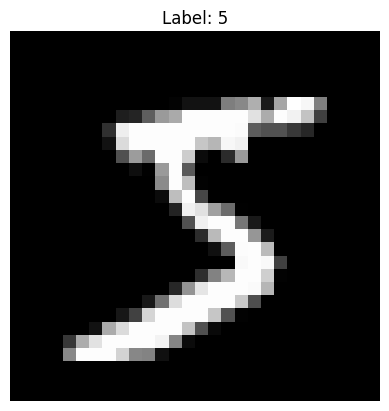

In [ ]:
image, label = train_dataset[0]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

Neural networks typically process data in batches rather than feeding the entire dataset into the model at once. A DataLoader helps us divide our dataset into smaller groups of images and labels.

We create two DataLoaders:

**train_loader**: Loads training images in batches of 64. shuffle=True randomly changes the order of the training images after each epoch, helping the model avoid relying on a fixed data order.

**test_loader**: Loads test images in batches of 64. shuffle=False keeps the test data in its original order, making evaluation more organized.

We then retrieve one batch from the training DataLoader to inspect its dimensions.

iter(train_loader) creates an iterator over the batches, and next() retrieves the first batch from that iterator.

The output should show:

Batch image shape: [64, 1, 28, 28]

Batch label shape: [64]

The first shape represents 64 images, each with 1 grayscale channel, 28 pixels in height, and 28 pixels in width. The second shape contains the 64 corresponding labels, one for each image.

In [ ]:
from torch.utils.data import DataLoader
train_loader = DataLoader(train_dataset,batch_size=64,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=64,shuffle=False)
images, labels = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

Batch image shape: torch.Size([64, 1, 28, 28])
Batch label shape: torch.Size([64])


Now, we will define our CNN using PyTorch's torch.nn module, which provides the layers needed to build a neural network.

Our model has two main stages:

1.Feature extraction: Convolutional layers identify patterns such as edges, curves, and shapes in the handwritten digits. Max pooling reduces the spatial dimensions of the feature maps.

2.Classification: Fully connected layers use the extracted features to predict which digit the image represents.

**Understanding the architecture:**

1.Convolutional layers (Conv2d): Apply learnable filters to the input images or feature maps to detect useful patterns.

2.ReLU activation: Introduces non-linearity, allowing the network to learn more complex patterns.

3.Max pooling (MaxPool2d): Reduces the height and width of feature maps by selecting the maximum value from each 2 × 2 region.

4.Flattening (view): Converts the feature maps into a one-dimensional feature vector for the fully connected layers.

5.Fully connected layers (Linear): Combine the extracted features to classify the image.

6.Output layer: Produces 10 scores, one for each digit from 0 to 9.

The following code defines the layers and the order in which an input image passes through them.

In [ ]:
import torch
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # TODO 1: Input is grayscale (1 channel); produce 32 feature maps.
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)

        # TODO 2: Map 32 feature maps to 64 feature maps.
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        # TODO 3: Keep 64 feature maps as output.
        self.conv3 = nn.Conv2d(64, 64, 3, padding=1)

        # TODO 4: Define 2x2 max pooling with stride 2.
        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 3 * 3, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))

        # Do the same for the third convolution layer.
        x = self.pool(torch.relu(self.conv3(x)))

        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

Before training our CNN, we need to check whether the model processes images correctly and produces outputs of the expected shape.

We'll first create an instance of our CNN class. Then, we'll retrieve one batch of images from the training DataLoader and pass those images through the model.

The model processes the images using the layers defined in forward() and returns its outputs.

We print the shapes of the input and output tensors to verify that everything is working as expected.

Input shape: [64, 1, 28, 28] - The batch contains 64 grayscale images, each measuring 28 × 28 pixels.

Output shape: [64, 10] - The model produces 10 scores for each image, one for each possible digit from 0 to 9.

At this stage, the model has not been trained. Its parameters are initialized with default random values, so its predictions are not yet meaningful.

This step is called a **forward pass**: data enters the network, moves through its layers, and produces an output without updating the model's parameters.

In [ ]:
model = CNN()
images, labels = next(iter(train_loader))
outputs = model(images)
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


Before training our CNN, we need two important components: a **loss function** and an **optimizer**.

The loss function measures how far the model's predictions are from the correct labels. The optimizer uses this information to adjust the model's learnable parameters and improve its predictions.

**CrossEntropyLoss**: Measures the difference between the model's predicted scores and the correct digit labels. It is commonly used for multi-class classification tasks like recognizing digits from 0 to 9.

**Adam optimizer**: Updates the model's parameters using gradients calculated during backpropagation. It adapts the learning rate for individual parameters to help the model learn effectively.

**Learning rate** (lr=0.001): Controls the size of the parameter updates made by the optimizer.

During training, the model will make predictions, calculate the loss, and use backpropagation to compute gradients. The Adam optimizer will then use these gradients to update the parameters, helping the CNN make better predictions over time.

In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

We are now ready to train our Convolutional Neural Network for 10 epochs. During training, the model learns to recognize patterns in handwritten digits by adjusting its parameters to reduce prediction errors.

For each batch of training images, the following steps take place:

1.Set training mode: model.train() enables training-specific behavior in the model.

2.Clear gradients: optimizer.zero_grad() resets gradients from the previous batch.

3.Forward pass: model(images) passes the images through the CNN to generate 10 scores for each image.

4.Calculate loss: criterion(outputs, labels) measures how well the predictions match the correct labels.

5.Backpropagation: loss.backward() calculates gradients that indicate how the parameters should change to reduce the loss.

6.Update parameters: optimizer.step() uses the gradients to update the model's learnable parameters.

7.Track performance: We accumulate the loss and count the correctly classified images to calculate the average loss and training accuracy.

After processing all the training batches in an epoch, we calculate the average loss and accuracy and store the loss in train_losses. These values help us monitor the model's learning progress.

Understanding the output:

Loss: Measures the model's prediction error. Lower values generally indicate better predictions on the training data.

Accuracy: The percentage of training images classified correctly.

Epoch: One complete pass through the training dataset.

As training progresses, we generally expect the loss to decrease and accuracy to increase. However, training accuracy alone does not tell us how well the model performs on unseen images. We will evaluate that separately using our test dataset.

## Training Functions

Before training our CNN, let's look at the functions we'll use.

- model(images) – Generates predictions for the input images.
- model.train() – Puts the model in training mode.
- optimizer.step() – Updates the model's weights.
- criterion(outputs, labels) – Calculates the loss by comparing predictions with correct labels.
- optimizer.zero_grad() – Clears previous gradients.
- loss.backward() – Calculates gradients using backpropagation.


In [ ]:
epochs = 10
train_losses = []

for epoch in range(epochs):
    # TO DO 1: Set the model to training mode
    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        # TO DO 2: Reset the gradients
        optimizer.zero_grad()

        # TO DO 3: Get predictions from the model
        outputs = model(images)

        # TO DO 4: Calculate the loss
        loss = criterion(outputs, labels)

        # TO DO 5: Calculate gradients
        loss.backward()

        # TO DO 6: Update the model's weights
        optimizer.step()

        running_loss += loss.item()

        # Here we get the predicted digit
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    # Calculating the average loss and accuracy
    epoch_loss = running_loss / len(train_loader)
    accuracy = 100 * correct / total
    train_losses.append(epoch_loss)
    print(f"Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Accuracy: {accuracy:.2f}%")

Epoch 1/10 | Loss: 0.2273 | Accuracy: 92.56%
Epoch 2/10 | Loss: 0.0560 | Accuracy: 98.23%
Epoch 3/10 | Loss: 0.0380 | Accuracy: 98.82%
Epoch 4/10 | Loss: 0.0302 | Accuracy: 99.09%
Epoch 5/10 | Loss: 0.0247 | Accuracy: 99.22%
Epoch 6/10 | Loss: 0.0212 | Accuracy: 99.32%
Epoch 7/10 | Loss: 0.0176 | Accuracy: 99.43%
Epoch 8/10 | Loss: 0.0155 | Accuracy: 99.48%
Epoch 9/10 | Loss: 0.0134 | Accuracy: 99.56%
Epoch 10/10 | Loss: 0.0136 | Accuracy: 99.57%


### Experiment: How Many Epochs Do We Need?

Now that you've trained your CNN, let's experiment!

1. Change epochs = 10 to epochs = 3, then run the training cell.
2. Try epochs = 5 and epochs = 15.
3. Observe how the training loss and accuracy change with each experiment.

**Think about it:**
- Does increasing the number of epochs always improve the model?
- At what point do the improvements become smaller?
- How would you decide when to stop training?

Now that our CNN has been trained, we need to evaluate how well it recognizes handwritten digits it has not seen during training.

We use the test dataset, which contains 10,000 images kept separate from the training process. This helps us measure how well the model generalizes to unseen data.

Here's what happens in this evaluation:

**model.eval()**: Switches the model to evaluation mode, changing the behavior of layers that act differently during training and evaluation.

**torch.no_grad()**: Disables gradient calculation because we are only making predictions, not updating the model's parameters. This reduces memory usage.

**Prediction**: Each batch of test images passes through the CNN, producing 10 scores per image. torch.max(outputs, 1) selects the digit with the highest score.

**Collecting predictions and labels**: all_preds stores the predicted digits, while all_labels stores the correct digits for comparison.

**Calculating accuracy**: accuracy_score() compares the predictions with the correct labels and calculates the percentage of correctly classified images.

Finally, we print the test accuracy as a percentage.

Before each experiment, run the cells that define the model and optimizer again. This ensures that training starts with fresh model weights. The optimizer.zero_grad() command inside the training loop clears gradients, but it does not reset the weights learned during previous training.

In [ ]:
from sklearn.metrics import accuracy_score
model.eval()
all_preds = []
all_labels = []
with torch.no_grad():
 for images, labels in test_loader:
  outputs = model(images)
  _, predicted = torch.max(outputs, 1)
  all_preds.extend(predicted.numpy())
  all_labels.extend(labels.numpy())
accuracy = accuracy_score(all_labels, all_preds) * 100
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 99.26%


Overall, our simple CNN has learned to recognize handwritten digits with high accuracy. This demonstrates how convolutional layers extract useful image features and how fully connected layers use those features to classify images into the 10 digit classes.